Data Preprocessing

In [ ]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv(r"online_shoppers_intention_uncleaned.csv")
print("Original Dataset Shape:", df.shape)
# 2. Display the first five rows
print("\nFirst Five Rows:")
print(df.head())
# 3. Check dataset information
print("\nDataset Information:")
df.info()
# 4. Check missing values
print("\nMissing Values Before Preprocessing:")
print(df.isnull().sum())
# 5. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())
# 6. Remove duplicate rows
df = df.drop_duplicates()
print("\nShape After Removing Duplicates:", df.shape)
# 7. Handle missing values
# Numerical columns -> fill with median
# Categorical columns -> fill with mode
for column in df.columns:
    if df[column].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[column]):
            df[column] = df[column].fillna(df[column].median())
        else:
            df[column] = df[column].fillna(df[column].mode()[0])
# 8. Remove unnecessary spaces from column names
df.columns = df.columns.str.strip()
# 9. Check data types
print("\nData Types:")
print(df.dtypes)
# 10. Check missing values after preprocessing
print("\nMissing Values After Preprocessing:")
print(df.isnull().sum())
# 11. Check duplicates after preprocessing
print("\nDuplicates After Preprocessing:")
print(df.duplicated().sum())
# 12. Display final dataset information
print("\nFinal Dataset Shape:", df.shape)
print("\nFinal Dataset Preview:")
print(df.head())
# 13. Save the preprocessed dataset
df.to_csv("preprocessed_dataset.csv", index=False)
print("\nData preprocessing completed successfully!")
print("Saved as preprocessed_dataset.csv")


Original Dataset Shape: (12390, 18)

First Five Rows:
   Administrative  Administrative_Duration  Informational  \
0             0.0                      0.0            0.0   
1             0.0                      0.0            0.0   
2             0.0                      0.0            0.0   
3             0.0                      0.0            0.0   
4             0.0                      0.0            0.0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0             1.0                 0.000000   
1                     0.0             2.0                64.000000   
2                     0.0             1.0                 0.000000   
3                     0.0             2.0                 2.666667   
4                     0.0            10.0               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0  Feb                1.0   
1   

C:\Users\battu\AppData\Local\Temp\ipykernel_24116\1648044723.py:39: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[column] = df[column].fillna(df[column].mode()[0])


EDA

Dataset Shape: (12299, 18)

First Five Rows:
   Administrative  Administrative_Duration  Informational  \
0             0.0                      0.0            0.0   
1             0.0                      0.0            0.0   
2             0.0                      0.0            0.0   
3             0.0                      0.0            0.0   
4             0.0                      0.0            0.0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0             1.0                 0.000000   
1                     0.0             2.0                64.000000   
2                     0.0             1.0                 0.000000   
3                     0.0             2.0                 2.666667   
4                     0.0            10.0               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0  Feb                1.0   
1         0.0

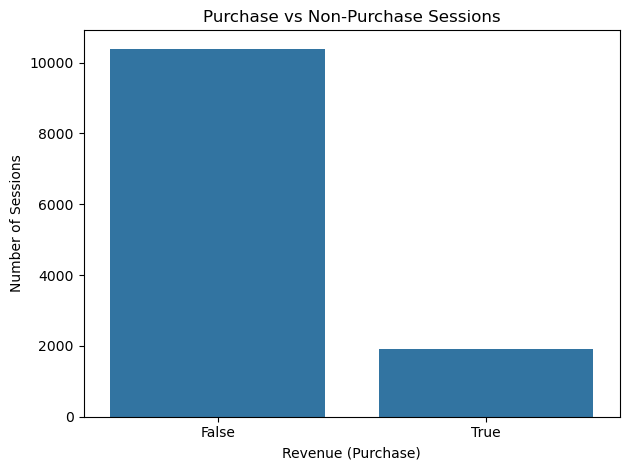

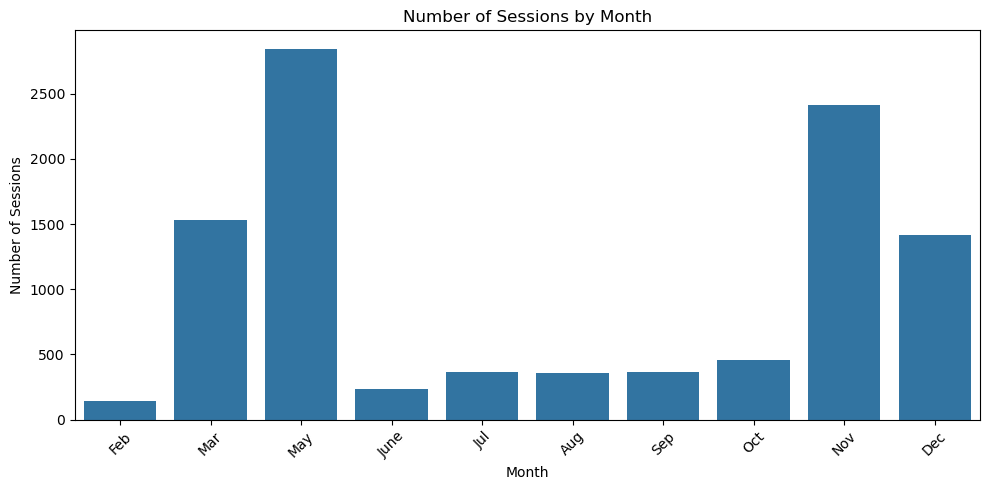


Monthly Purchase Conversion Rate (%):
Month
Oct      33.333333
oct      25.974026
Nov      25.642088
Nov      25.000000
NOV      24.645390
 SEP     22.222222
Oct      19.956616
Sep      18.232044
Aug      17.877095
Jul      15.531335
dec      15.254237
JUL      13.559322
aug      12.857143
Dec      11.935028
MAY      11.525424
May      11.040788
June     10.822511
Mar      10.392157
march     8.841463
 june     7.272727
Feb       2.127660
Dec       0.000000
Feb       0.000000
NOV       0.000000
May       0.000000
MAY       0.000000
Mar       0.000000
Name: Revenue, dtype: float64


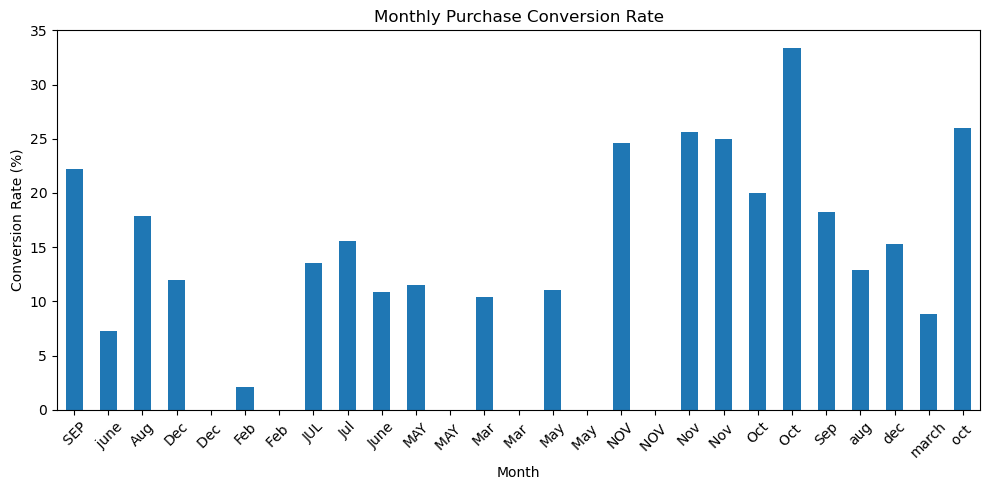


Visitor Type Distribution:
VisitorType
Returning_Visitor    8530
Returning Visitor    2011
New_Visitor          1329
 New_Visitor          348
Other                  70
other                  11
Name: count, dtype: int64


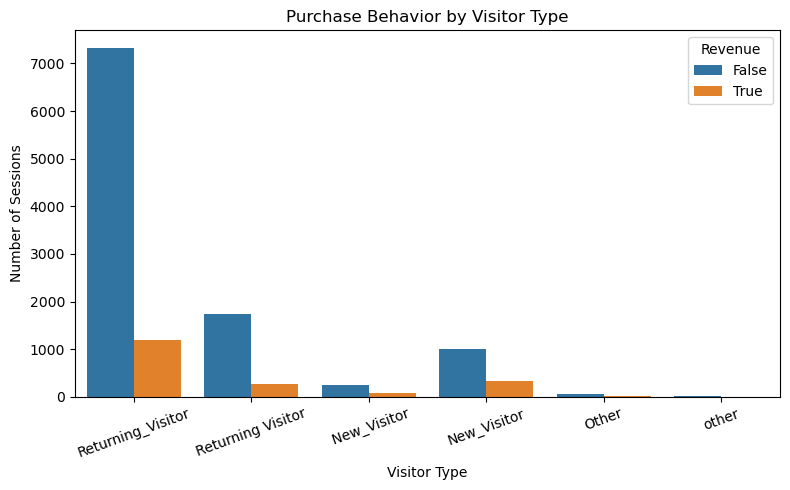


Visitor Type Conversion Rate (%):
VisitorType
 New_Visitor         26.149425
New_Visitor          24.680211
Other                21.428571
Returning_Visitor    14.103165
Returning Visitor    13.525609
other                 9.090909
Name: Revenue, dtype: float64


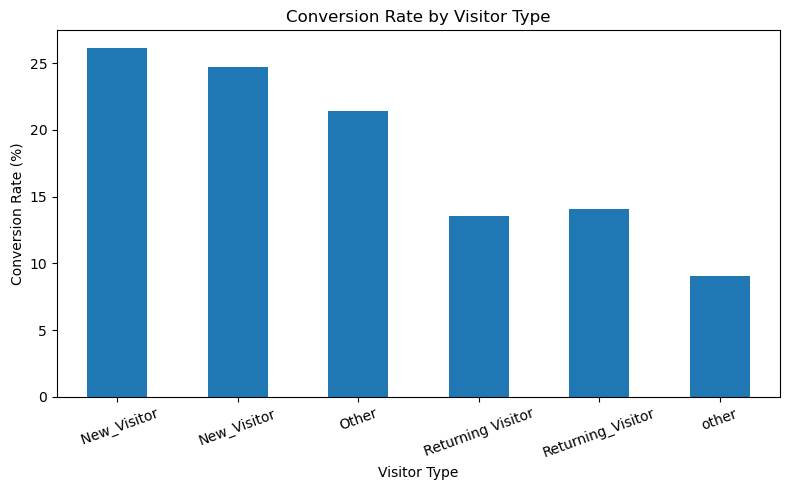

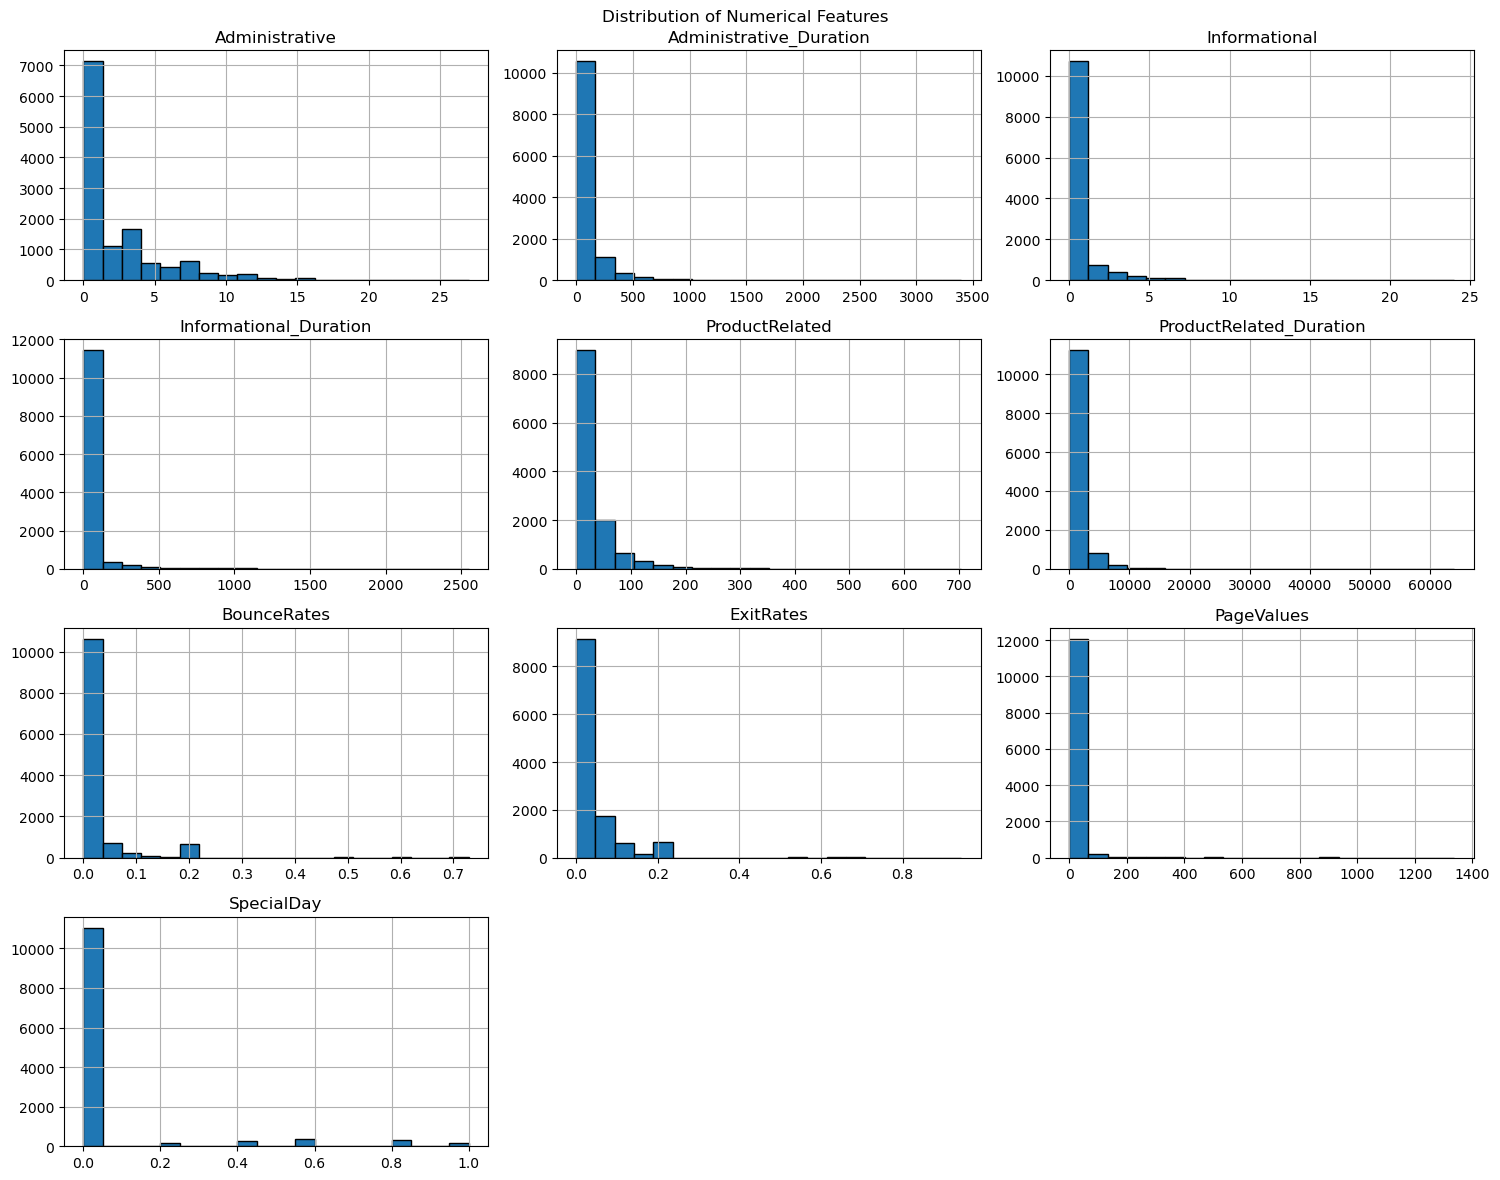

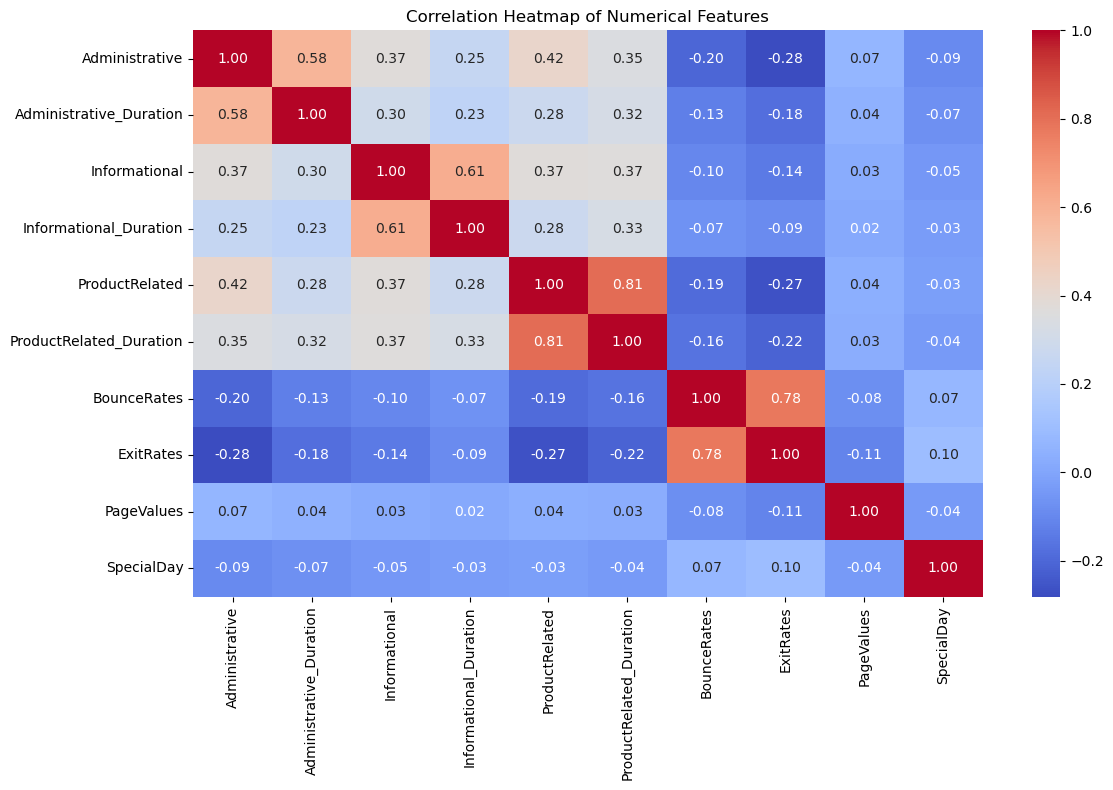

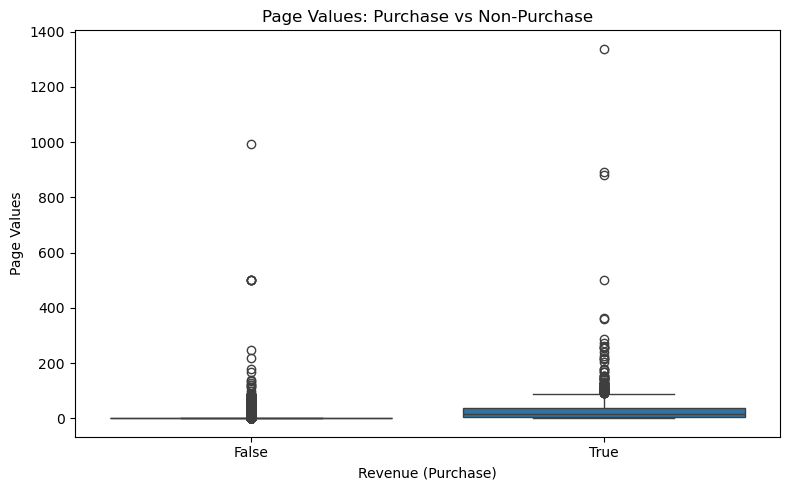

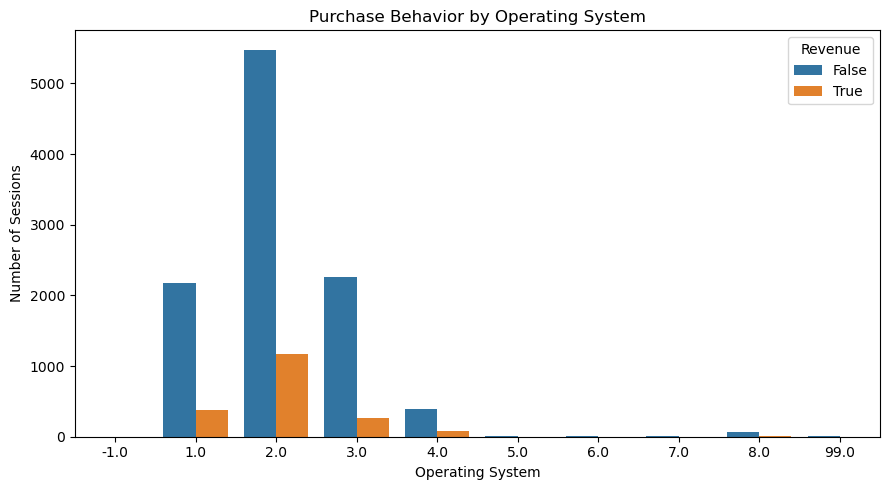


========== EDA SUMMARY ==========
Total Sessions: 12299
Purchase Sessions: 1910
Non-Purchase Sessions: 10389
Overall Conversion Rate: 15.53 %

EDA completed successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the preprocessed dataset
df = pd.read_csv("preprocessed_dataset.csv")
# 2. Display basic information
print("Dataset Shape:", df.shape)
print("\nFirst Five Rows:")
print(df.head())
print("\nDataset Information:")
df.info()
# 3. Statistical summary
print("\nStatistical Summary:")
print(df.describe())
# 4. Check data types
print("\nColumn Data Types:")
print(df.dtypes)
# 5. Check missing values
print("\nMissing Values:")
print(df.isnull().sum())
# 6. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())
# 7. Count purchase and non-purchase sessions
print("\nPurchase Distribution:")
print(df["Revenue"].value_counts())
print("\nPurchase Percentage:")
print(df["Revenue"].value_counts(normalize=True) * 100)
# 8. Visualize purchase distribution
sns.countplot(data=df, x="Revenue")
plt.title("Purchase vs Non-Purchase Sessions")
plt.xlabel("Revenue (Purchase)")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()
# 9. Analyze visitors by month
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Month", order=[
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
])
plt.title("Number of Sessions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# 10. Analyze purchase conversion by month
monthly_conversion = df.groupby("Month")["Revenue"].mean() * 100
print("\nMonthly Purchase Conversion Rate (%):")
print(monthly_conversion.sort_values(ascending=False))
monthly_conversion.plot(kind="bar", figsize=(10, 5))
plt.title("Monthly Purchase Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# 11. Analyze visitor type
print("\nVisitor Type Distribution:")
print(df["VisitorType"].value_counts())
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="VisitorType", hue="Revenue")
plt.title("Purchase Behavior by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
# 12. Analyze visitor type conversion rate
visitor_conversion = df.groupby("VisitorType")["Revenue"].mean() * 100
print("\nVisitor Type Conversion Rate (%):")
print(visitor_conversion.sort_values(ascending=False))
visitor_conversion.plot(kind="bar", figsize=(8, 5))
plt.title("Conversion Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
# 13. Analyze numerical features
numerical_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]
df[numerical_columns].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()
# 14. Correlation heatmap
plt.figure(figsize=(12, 8))
correlation = df[numerical_columns].corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()
# 15. Compare page values for purchase sessions
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Revenue", y="PageValues")
plt.title("Page Values: Purchase vs Non-Purchase")
plt.xlabel("Revenue (Purchase)")
plt.ylabel("Page Values")
plt.tight_layout()
plt.show()
# 16. Analyze operating systems
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="OperatingSystems", hue="Revenue")
plt.title("Purchase Behavior by Operating System")
plt.xlabel("Operating System")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()
# 17. Final EDA summary
print("\n========== EDA SUMMARY ==========")
print("Total Sessions:", len(df))
print("Purchase Sessions:", int(df["Revenue"].sum()))
print("Non-Purchase Sessions:", int((~df["Revenue"]).sum()))
print("Overall Conversion Rate:",round(df["Revenue"].mean() * 100, 2), "%")
print("\nEDA completed successfully!")


Feature Selection

Dataset Shape: (12299, 18)

Correlation with Revenue:
PageValues                       0.334335
ProductRelated                   0.156636
ProductRelated_Duration          0.144039
Administrative                   0.138135
Month_Nov                        0.137975
Informational                    0.093800
Administrative_Duration          0.089317
VisitorType_New_Visitor          0.087937
Informational_Duration           0.070380
Month_NOV                        0.055176
Weekend                          0.028758
Browser                          0.025770
Month_Oct                        0.024120
Month_oct                        0.022889
Month_Sep                        0.012993
VisitorType_Other                0.012322
Month_Aug                        0.011222
Month_Oct                        0.007678
Month_Nov                        0.004716
Month_Jul                        0.000008
Month_dec                       -0.001192
Month_JUL                       -0.003777
Month_NOV             

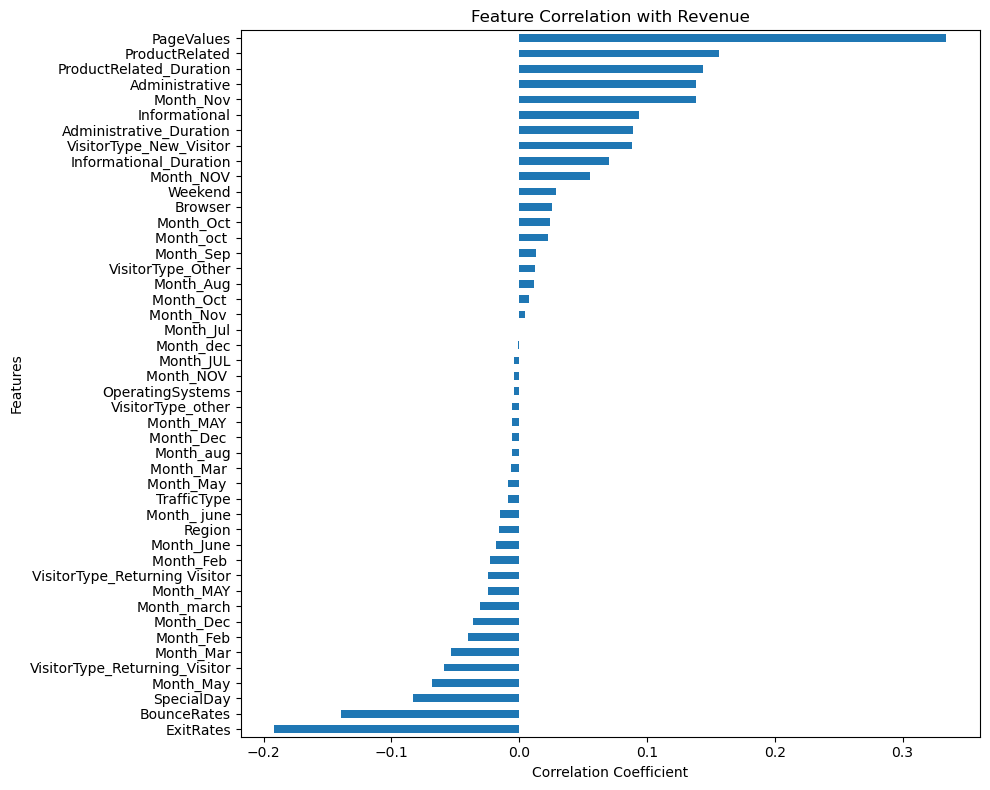


Selected Features:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month_Mar', 'Month_May', 'Month_NOV', 'Month_Nov', 'VisitorType_New_Visitor', 'VisitorType_Returning_Visitor']

Selected Feature Dataset Shape: (12299, 16)
Target Dataset Shape: (12299,)

Feature selection completed successfully!
Saved as selected_features_dataset.csv


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Load preprocessed dataset
df = pd.read_csv("preprocessed_dataset.csv")
print("Dataset Shape:", df.shape)
# 2. Convert target column into numerical values
df["Revenue"] = df["Revenue"].map({True: 1,False: 0,"True": 1,"False": 0})
# 3. Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(df,drop_first=True,dtype=int)
# 4. Calculate correlation matrix
correlation_matrix = df_encoded.corr()
# 5. Display correlation with target variable
target_correlation = correlation_matrix["Revenue"].drop("Revenue")
print("\nCorrelation with Revenue:")
print(target_correlation.sort_values(ascending=False))
# 6. Visualize correlation with Revenue
target_correlation.sort_values().plot(kind="barh",figsize=(10, 8))
plt.title("Feature Correlation with Revenue")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Features")
plt.tight_layout()
plt.show()
# 7. Select features using correlation threshold
threshold = 0.05
selected_features = target_correlation[target_correlation.abs() >= threshold].index.tolist()
print("\nSelected Features:")
print(selected_features)
# 8. Create selected-feature dataset
X = df_encoded[selected_features]
y = df_encoded["Revenue"]
print("\nSelected Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)
# 9. Save selected features
selected_df = X.copy()
selected_df["Revenue"] = y
selected_df.to_csv("selected_features_dataset.csv",index=False)
print("\nFeature selection completed successfully!")
print("Saved as selected_features_dataset.csv")


Train-Test-Split

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load selected features dataset
df = pd.read_csv("selected_features_dataset.csv")
print("Dataset Shape:", df.shape)
# 2. Separate input features (X) and target (y)
X = df.drop("Revenue", axis=1)
y = df["Revenue"]
print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)
# 3. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
# 4. Display dataset sizes
print("\nTraining and Testing Results")
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)
# 5. Check class distribution
print("\nTraining Set Purchase Distribution:")
print(y_train.value_counts())
print("\nTesting Set Purchase Distribution:")
print(y_test.value_counts())
# 6. Save training and testing datasets
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
y_train.to_csv("y_train.csv", index=False)
y_test.to_csv("y_test.csv", index=False)
print("\nTrain-test split completed successfully!")
print("Saved files:")
print("X_train.csv")
print("X_test.csv")
print("y_train.csv")
print("y_test.csv")

Dataset Shape: (12299, 17)

Input Features Shape: (12299, 16)
Target Shape: (12299,)

Training and Testing Results
Training Features: (9839, 16)
Testing Features: (2460, 16)
Training Target: (9839,)
Testing Target: (2460,)

Training Set Purchase Distribution:
Revenue
0    8311
1    1528
Name: count, dtype: int64

Testing Set Purchase Distribution:
Revenue
0    2078
1     382
Name: count, dtype: int64

Train-test split completed successfully!
Saved files:
X_train.csv
X_test.csv
y_train.csv
y_test.csv


Model Training

In [8]:
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Load training datasets
X_train = pd.read_csv("X_train.csv")
y_train = pd.read_csv("y_train.csv").squeeze("columns")
print("Training Features Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)
# 2. Create the machine learning model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])
# 3. Train the model
model.fit(X_train, y_train)
print("\nModel training completed successfully!")
# 4. Display training accuracy
training_accuracy = model.score(X_train, y_train)
print("Training Accuracy:",round(training_accuracy * 100, 2),"%")
# 5. Save the trained model
joblib.dump(model, "purchase_conversion_model.pkl")
print("\nModel saved successfully!")
print("File: purchase_conversion_model.pkl")


Training Features Shape: (9839, 16)
Training Target Shape: (9839,)

Model training completed successfully!
Training Accuracy: 85.95 %

Model saved successfully!
File: purchase_conversion_model.pkl


PREDICTION

In [9]:
import pandas as pd
import joblib

# 1. Load model and dataset
model = joblib.load("purchase_conversion_model.pkl")
df = pd.read_csv("selected_features_dataset.csv")
feature_names = df.drop(columns=["Revenue"]).columns.tolist()
print("\n===== ONLINE PURCHASE CONVERSION ADVISOR =====")
print("Enter 3 values: pages visited, duration, page value")
try:
    # 2. Take all 3 inputs in one line
    values = input("Enter values (e.g. 10,300,10): ").split(",")
    if len(values) != 3:
        raise ValueError("Enter exactly 3 values.")
    pages, duration, page_value = map(float, values)
    if pages < 0 or duration < 0 or page_value < 0:
        raise ValueError("Values cannot be negative.")
    # 3. Use median values for remaining features
    input_data = df[feature_names].median().to_dict()
    # 4. Update the three selected inputs
    feature_mapping = {
        "ProductRelated": pages,
        "ProductRelated_Duration": duration,
        "PageValues": page_value
    }
    for feature, value in feature_mapping.items():
        if feature in input_data:
            input_data[feature] = value
    # 5. Prepare input in correct feature order
    input_df = pd.DataFrame([input_data], columns=feature_names)
    # 6. Predict
    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]
    classes = list(model.classes_)
    purchase_probability = probabilities[classes.index(1)] * 100
    # 7. Display result
    print("\n========== PREDICTION RESULT ==========")
    print("Prediction:","Purchase Likely" if prediction == 1 else "Purchase Unlikely")
    print(f"Purchase Probability: {purchase_probability:.2f}%")

    if purchase_probability >= 70:
        priority = "High"
    elif purchase_probability >= 40:
        priority = "Medium"
    else:
        priority = "Low"

    print("Conversion Priority:", priority)
    print("\nPrediction completed successfully!")

except ValueError as error:
    print("\nInput Error:", error)

except Exception as error:
    print("\nError:", error)



===== ONLINE PURCHASE CONVERSION ADVISOR =====
Enter 3 values: pages visited, duration, page value

========== PREDICTION RESULT ==========
Prediction: Purchase Likely
Purchase Probability: 61.95%
Conversion Priority: Medium

Prediction completed successfully!


Model Evaluation

===== MODEL EVALUATION =====

Accuracy : 85.37 %
Precision: 52.06 %
Recall   : 72.77 %
F1-Score : 60.7 %
ROC-AUC  : 0.8849

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.88      0.91      2078
           1       0.52      0.73      0.61       382

    accuracy                           0.85      2460
   macro avg       0.73      0.80      0.76      2460
weighted avg       0.88      0.85      0.86      2460



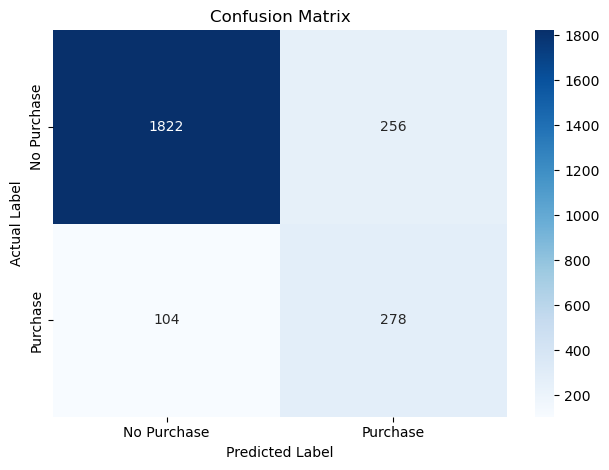

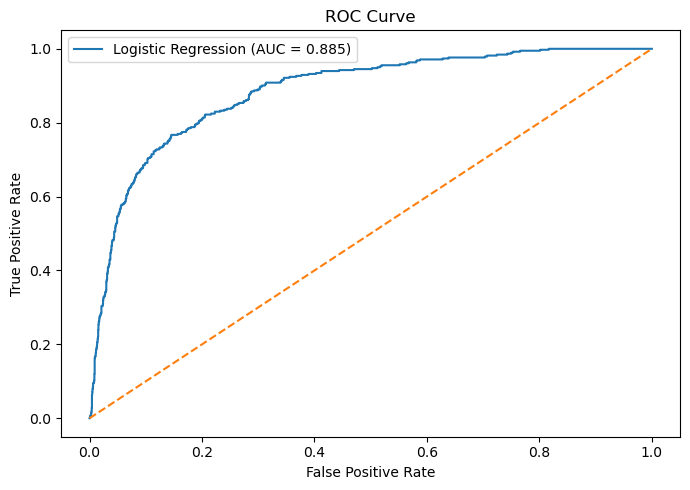


Evaluation completed successfully!
Metrics saved to evaluation_metrics.csv


In [10]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# 1. Load trained model and testing data
model = joblib.load("purchase_conversion_model.pkl")
X_test = pd.read_csv("X_test.csv")
y_test = pd.read_csv("y_test.csv").squeeze("columns")
print("===== MODEL EVALUATION =====")
# 2. Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
# 3. Calculate performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
print("\nAccuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1-Score :", round(f1 * 100, 2), "%")
# 4. ROC-AUC score
if y_test.nunique() == 2:
    auc = roc_auc_score(y_test, y_prob)
    print("ROC-AUC  :", round(auc, 4))
# 5. Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))
# 6. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 7. ROC curve
if y_test.nunique() == 2:
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    plt.figure(figsize=(7, 5))
    plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.title("ROC Curve")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.tight_layout()
    plt.show()

# 8. Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1]
})

metrics.to_csv("evaluation_metrics.csv", index=False)

print("\nEvaluation completed successfully!")
print("Metrics saved to evaluation_metrics.csv")
